# <font color="red">Read data</font>

In [137]:
import pandas as pd

data = pd.read_excel("data.xlsx")

data = data[data.Country != "Israel"]



# <font color="red">Explore et analyse data</font>

## <font color="green">general data</font>

In [ ]:
# # shape, size
# print("shape:", data.shape)

# # columns
# print(data.columns)

# # types
# print(data.dtypes)

# # info
# print(data.info())

# # duplucated
# print(data.duplicated())



Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


## <font color="green">clean data</font>

In [138]:
import datetime as dt
def clean_na_neg():
    global data
    
    data = data.dropna(subset=["CustomerID"])
    
    data = data[data.Quantity > 0]
    data["Description"] = data["Description"].fillna("No desc")
    
    print(data.shape) 
    
def convert_types():
    data["CustomerID"]= data["CustomerID"].astype("int64")
    data["InvoiceNo"] = data["InvoiceNo"].astype("str")
    data["StockCode"] = data["StockCode"].astype("str")
    data["Description"] = data["Description"].astype("str")
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
    
clean_na_neg()
convert_types()

print(data.info())  
    
    

(397676, 8)
<class 'pandas.DataFrame'>
Index: 397676 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397676 non-null  str           
 1   StockCode    397676 non-null  str           
 2   Description  397676 non-null  str           
 3   Quantity     397676 non-null  int64         
 4   InvoiceDate  397676 non-null  datetime64[us]
 5   UnitPrice    397676 non-null  float64       
 6   CustomerID   397676 non-null  int64         
 7   Country      397676 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 46.7 MB
None


## <font color="green">RFM</font>

In [152]:
def get_recency():
    # connait le fédality du clients 
    def calculate_date_diff(client_time):
        now = dt.datetime.now()
        diff: pd.Series = now - client_time
        return diff.dt.days

    last_sales  = data.groupby("CustomerID")["InvoiceDate"].max()

    recency = calculate_date_diff(last_sales)

    return recency 
    

def get_frequence():
    # connait le nomber de transaction fait par clients
    counts = data["CustomerID"].value_counts()
    return counts
    
def get_montary():
    # connait combien du argent gaspillé 
    max_sales = data.assign(total= data["Quantity"]* data["UnitPrice"]).groupby("CustomerID")["total"].sum()
    return max_sales

recency, frequence, montary = get_recency(), get_frequence(), get_montary()


ids = data.CustomerID.unique()

clients_rfm = {
    "ClientId": [],
    "recency": [],
    "frequence": [],
    "montary": []
}
for i in ids:
    clients_rfm["ClientId"].append(i)
    clients_rfm["recency"].append(recency[i])
    clients_rfm["frequence"].append(frequence[i])
    clients_rfm["montary"].append(montary[i])
    
df_clients_rfm = pd.DataFrame(clients_rfm)    
print(df_clients_rfm.head())


    

   ClientId  recency  frequence  montary
0     17850     5779        297  5391.21
1     13047     5438        172  3237.54
2     12583     5409        247  7281.38
3     13748     5502         28   948.25
4     15100     5740          3   876.00


## <font color="green">preparation des variables pour claustring</font>

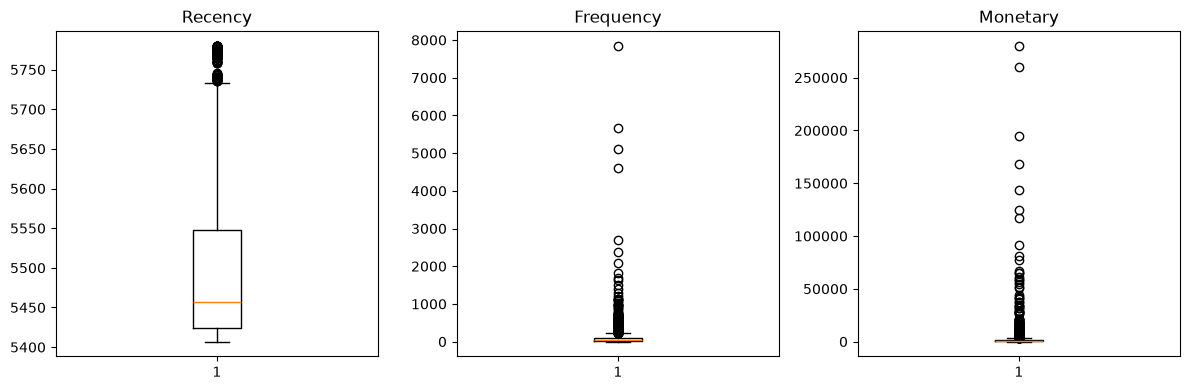

,recency,frequence,montary
count,4336.000000,4336.000000,4336.000000
mean,5499.029751,91.714945,2053.548481
std,100.037457,228.865963,8991.208553
min,5407.000000,1.000000,0.000000
25%,5424.000000,17.000000,307.322500
50%,5457.000000,41.000000,673.855000
75%,5548.250000,100.000000,1661.357500
max,5780.000000,7847.000000,280206.020000


In [155]:
import matplotlib.pyplot as plt

recency = df_clients_rfm["recency"]
frequence = df_clients_rfm["frequence"]
montary = df_clients_rfm["montary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].boxplot(recency)
axes[0].set_title("Recency")

axes[1].boxplot(frequence)
axes[1].set_title("Frequency")

axes[2].boxplot(montary)
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()

df_clients_rfm[["recency", "frequence", "montary"]].describe()


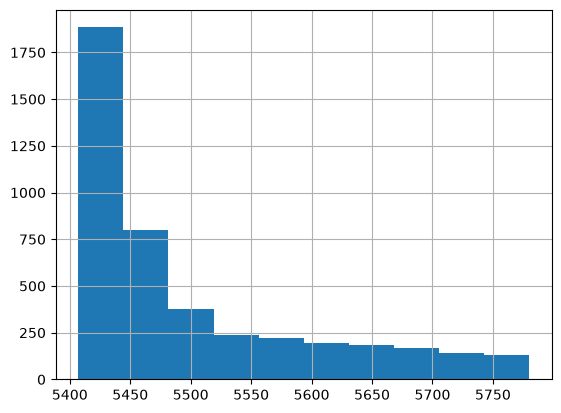

In [156]:
df_clients_rfm["recency"].hist()
plt.show()